In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# The notebook is located in the analysis folder; so above that is the project root directory.
project_root = Path.cwd().parent

# Read the results of the completed experiments
csv_path = project_root / 'results' / 'timings.csv'
df = pd.read_csv(csv_path, dtype={'code_version': str})

# Check the location of the read and the size of the data.
print(f'File location：{csv_path}')
print(f'Number of data rows：{len(df)}')
print(f'Counting the numbers：{len(df.columns)}')

# Count the number of rows based on the experiment name and code version
df.groupby(['experiment', 'code_version']).size().rename('rows')

File location：/project/results/timings.csv
Number of data rows：2100
Counting the numbers：33


experiment       code_version
CORE             f5dfa0b         210
E1_build_memory  03d990e         210
E5_insert_order  03d990e         840
                 870c3a9         840
Name: rows, dtype: int64

In [3]:
# Lock the two rounds of E5 that have been verified to avoid including any additional results added later.
sessions = ['240c73092ceb', '558bce9a341a']

# Filter the matching query results of the ordered list on this machine
e5_lookup = df.loc[
    df['session_id'].isin(sessions)
    & (df['experiment'] == 'E5_insert_order')
    & (df['member'] == 'fenghao')
    & (df['machine_id'] == 'fenghao-pc')
    & (df['index_type'] == 'sorted_list')
    & (df['operation'] == 'point_hit')
].copy()

# Convert the total time consumption into the time consumption for a single query, with the unit being microseconds.
e5_lookup['us_per_query'] = (
    e5_lookup['total_ns'] / e5_lookup['n_ops'] / 1000
)

# Convert the total number of comparisons into the average number of comparisons per query
e5_lookup['comparisons_per_query'] = (
    e5_lookup['comparisons'] / e5_lookup['n_ops']
)

# Check the number of rows after filtering, as well as the quantities of each version and each insertion sequence.
print(f'Number of rows after filtering：{len(e5_lookup)}')
e5_lookup.groupby(['code_version', 'insert_order']).size().rename('rows')

Number of rows after filtering：120


code_version  insert_order 
03d990e       nearly_sorted    15
              random           15
              reversed         15
              sorted           15
870c3a9       nearly_sorted    15
              random           15
              reversed         15
              sorted           15
Name: rows, dtype: int64

In [4]:
# Summarize separately by code version, data size and insertion order.
e5_summary = (
    e5_lookup
    .groupby(['code_version', 'n_keys', 'insert_order'], as_index=False)
    .agg(
        reps=('rep', 'size'),
        mean_us=('us_per_query', 'mean'),
        std_us=('us_per_query', 'std'),
        median_us=('us_per_query', 'median'),
        mean_comparisons=('comparisons_per_query', 'mean'),
    )
    .sort_values(['insert_order', 'n_keys', 'code_version'])
)

# Confirm that each configuration has five repeated measurements.
assert e5_summary['reps'].eq(5).all(), 'Each configuration should have 5 repetitions.'

# First, display the randomly inserted results; the other three sequences have also been saved in the summary table.
e5_summary.loc[e5_summary['insert_order'] == 'random'].round(3)

,code_version,n_keys,insert_order,reps,mean_us,std_us,median_us,mean_comparisons
1,03d990e,1000,random,5,17.593,0.210,17.582,500.733
13,870c3a9,1000,random,5,0.830,0.006,0.829,10.976
5,03d990e,10000,random,5,214.401,17.893,207.167,5052.456
17,870c3a9,10000,random,5,1.176,0.072,1.196,14.386
9,03d990e,100000,random,5,2242.143,20.743,2236.230,51742.148
21,870c3a9,100000,random,5,1.974,0.216,2.014,17.663


In [5]:
# The columns required for comparing before and after selections
metrics = ['n_keys', 'insert_order', 'mean_us', 'mean_comparisons']

# Separately extract the summary results before and after the repair process.
before = e5_summary.loc[e5_summary['code_version'] == '03d990e', metrics]
after = e5_summary.loc[e5_summary['code_version'] == '870c3a9', metrics]

# Pair according to the same data size and insertion order
comparison = before.merge(
    after,
    on=['n_keys', 'insert_order'],
    suffixes=('_before', '_after'),
    validate='one_to_one',
)

# Speedup factor = Average time before repair / Average time after repair
comparison['speedup'] = (
    comparison['mean_us_before'] / comparison['mean_us_after']
)

# Sort the sequence and retain the complete accuracy for subsequent calculations.
comparison = comparison.sort_values(
    ['insert_order', 'n_keys']
).reset_index(drop=True)

# First, display the randomly inserted comparison table; only retain three decimal places when displaying.
comparison.loc[comparison['insert_order'] == 'random'].round(3)

,n_keys,insert_order,mean_us_before,mean_comparisons_before,mean_us_after,mean_comparisons_after,speedup
3,1000,random,17.593,500.733,0.830,10.976,21.184
4,10000,random,214.401,5052.456,1.176,14.386,182.276
5,100000,random,2242.143,51742.148,1.974,17.663,1135.632


The picture has been saved：/project/analysis/figures_INC01/INC-01_lookup_time.png


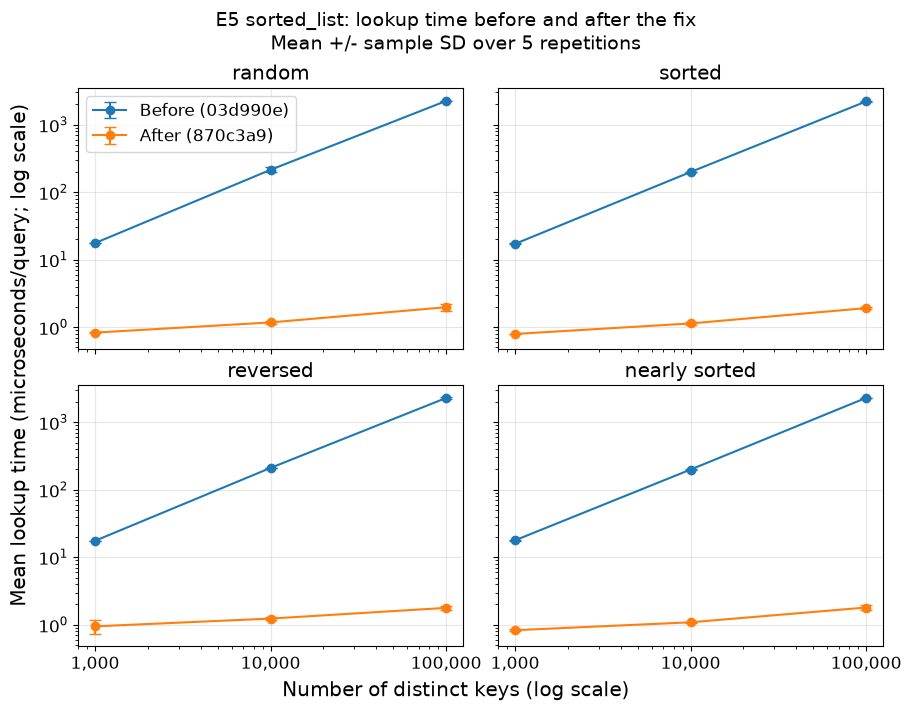

In [6]:
# Set the font size and create a directory for saving images
plt.rcParams.update({'font.size': 12})
fig_dir = project_root / 'analysis' / 'figures_INC01'
fig_dir.mkdir(parents=True, exist_ok=True)

# Four insertion sequences, as well as the version labels before and after the repair
orders = ['random', 'sorted', 'reversed', 'nearly_sorted']
versions = {
    '03d990e': 'Before (03d990e)',
    '870c3a9': 'After (870c3a9)',
}

# Create four subplots that share the same coordinate range
fig, axes = plt.subplots(
    2, 2, figsize=(9, 7),
    sharex=True, sharey=True,
    constrained_layout=True,
)

for ax, order in zip(axes.flat, orders):
    for version, label in versions.items():
        # Retrieve the three data sizes of the current sequence and the current version.
        data = e5_summary.loc[
            (e5_summary['insert_order'] == order)
            & (e5_summary['code_version'] == version)
        ].sort_values('n_keys')

        # The dots represent the average time consumption, while the error bars indicate the sample standard deviation of the results from five repetitions.
        ax.errorbar(
            data['n_keys'], data['mean_us'],
            yerr=data['std_us'],
            fmt='o-', capsize=4, label=label,
        )

    # Use logarithmic coordinates to display the scale growth and the significant time gap
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(800, 125000)
    ax.set_xticks(
        [1000, 10000, 100000],
        ['1,000', '10,000', '100,000'],
    )
    ax.set_title(order.replace('_', ' '))
    ax.grid(True, which='major', alpha=0.3)

# Add legends, coordinate explanations and titles
axes[0, 0].legend()
fig.supxlabel('Number of distinct keys (log scale)')
fig.supylabel('Mean lookup time (microseconds/query; log scale)')
fig.suptitle(
    'E5 sorted_list: lookup time before and after the fix\n'
    'Mean +/- sample SD over 5 repetitions',
    fontsize=14,
)

# Save plot
fig_path = fig_dir / 'INC-01_lookup_time.png'
fig.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f'The picture has been saved：{fig_path}')

plt.show()

The picture has been saved：/project/analysis/figures_INC01/INC-01_lookup_comparisons.png


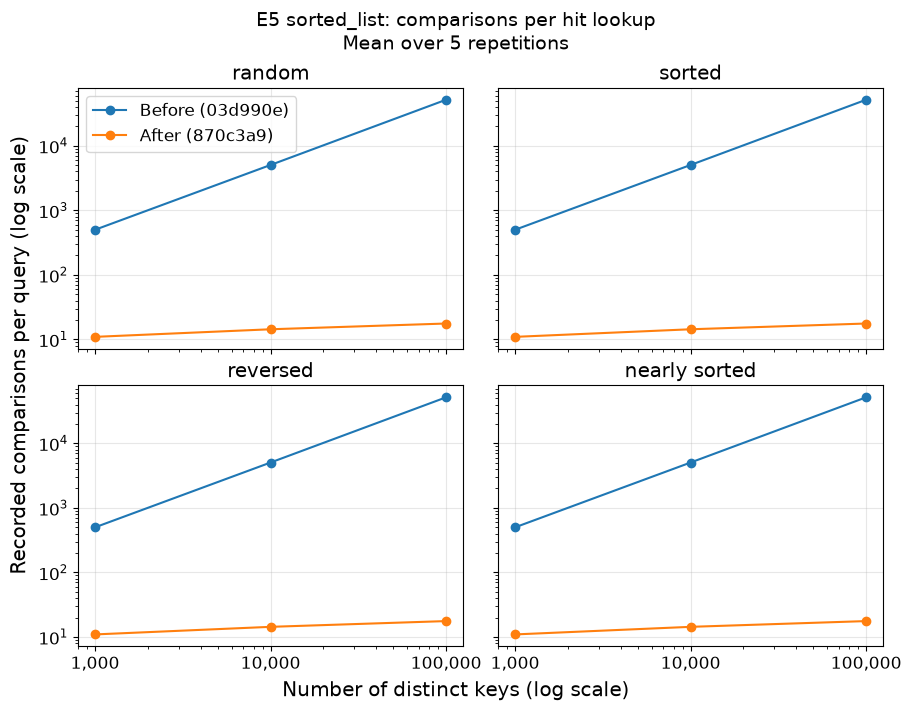

In [7]:
# Reuse the previously defined variables 'orders', 'versions', and the image directory 'fig_dir'
fig_comp, axes_comp = plt.subplots(
    2, 2, figsize=(9, 7),
    sharex=True, sharey=True,
    constrained_layout=True,
)

for ax, order in zip(axes_comp.flat, orders):
    for version, label in versions.items():
        # Retrieve the current insertion order and code version results
        data = e5_summary.loc[
            (e5_summary['insert_order'] == order)
            & (e5_summary['code_version'] == version)
        ].sort_values('n_keys')

        # Draw the average number of comparisons for each query record
        ax.plot(
            data['n_keys'], data['mean_comparisons'],
            'o-', label=label,
        )

    # Use the same horizontal axis range as the time-consuming graph and logarithmic scale
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(800, 125000)
    ax.set_xticks(
        [1000, 10000, 100000],
        ['1,000', '10,000', '100,000'],
    )
    ax.set_title(order.replace('_', ' '))
    ax.grid(True, which='major', alpha=0.3)

# Add legends, coordinate explanations and titles
axes_comp[0, 0].legend()
fig_comp.supxlabel('Number of distinct keys (log scale)')
fig_comp.supylabel('Recorded comparisons per query (log scale)')
fig_comp.suptitle(
    'E5 sorted_list: comparisons per hit lookup\n'
    'Mean over 5 repetitions',
    fontsize=14,
)

# Save the comparison frequency graph
comparison_fig_path = fig_dir / 'INC-01_lookup_comparisons.png'
fig_comp.savefig(comparison_fig_path, dpi=300, bbox_inches='tight')
print(f'The picture has been saved：{comparison_fig_path}')

plt.show()

In [8]:
# Create the directory for saving the table of this repair operation
table_dir = project_root / 'analysis' / 'tables_INC01'
table_dir.mkdir(parents=True, exist_ok=True)

# Save the statistics for each version, each scale, and each insertion sequence
summary_path = table_dir / 'INC-01_lookup_summary.csv'
e5_summary.to_csv(summary_path, index=False, encoding='utf-8-sig')

# Save the paired results and the speed-up factor before and after the repair.
comparison_path = table_dir / 'INC-01_lookup_comparison.csv'
comparison.to_csv(comparison_path, index=False, encoding='utf-8-sig')

# Display the save location and the number of data rows
print(f'Statistical summary table：{summary_path}，total {len(e5_summary)} rows')
print(f'Comparison Table Before and After：{comparison_path}，total {len(comparison)} rows')

Statistical summary table：/project/analysis/tables_INC01/INC-01_lookup_summary.csv，total 24 rows
Comparison Table Before and After：/project/analysis/tables_INC01/INC-01_lookup_comparison.csv，total 12 rows


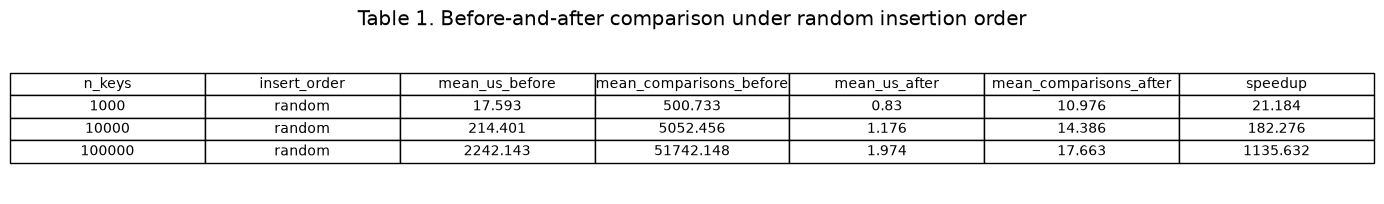

Saved to: /project/analysis/figures_INC01/INC01_random_order_before_after_table.png


In [9]:
# Retrieve the table to be displayed
table_data = (
    comparison.loc[comparison['insert_order'] == 'random', [
        'n_keys',
        'insert_order',
        'mean_us_before',
        'mean_comparisons_before',
        'mean_us_after',
        'mean_comparisons_after',
        'speedup'
    ]]
    .round(3)
    .reset_index(drop=True)
)

# file name
output_file = fig_dir / "INC01_random_order_before_after_table.png"

# plot
fig, ax = plt.subplots(figsize=(14, 2.2))
ax.axis('off')

tbl = ax.table(
    cellText=table_data.values,
    colLabels=table_data.columns,
    cellLoc='center',
    loc='center'
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1, 1.5)

# take title
plt.title(
    "Table 1. Before-and-after comparison under random insertion order",
    pad=12
)

plt.tight_layout()

# save plot
plt.savefig(output_file, dpi=300, bbox_inches='tight')
plt.show()

print(f"Saved to: {output_file}")

In [10]:
import sys

# Enable the Notebook files in the "analysis" directory to be able to import the project modules
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from datagen.synthetic import random_keys
from indexes.sorted_list import SortedListIndex

# Generate parameters using the same keys as those of E5
structure_keys = random_keys(100_000, length=8, seed=4300)

# Maintain the same key and record number correspondence as in E5
structure_row_ids = {
    key: row_id
    for row_id, key in enumerate(structure_keys)
}

# Insert in ascending order, corresponding to the sorted configuration of E5
structure_index = SortedListIndex()
for key in sorted(structure_keys):
    structure_index.insert(key, structure_row_ids[key])

# Read the actual structural information
structure_index.structure_info()

{'distinct_keys': 100000}